# Observing the Sun using Coronagraphs (3/3)

This notebook is the third of three notebooks and it displays coronagraph images from the [LASCO instrument](https://lasco-www.nrl.navy.mil/index.php?p=content/intro) on the [SOHO](https://soho.nascom.nasa.gov) spacecraft. The images are whitelight images of the solar corona with the Sun eclipsed by an occulting disk. The image is formed visible light scattering off the plasma that makes up the outer corona of the Sun. Ground based coroagraphs have been in use for a very long time but are of limted value because of atmospheric scattering. The Sun itself is blocked by an "occulting" disk so that it does not dominate the image. We have been routinely observing the Sun using space based coronagraphs since the [SkyLab mission](https://en.wikipedia.org/wiki/Skylab) in the 1970's and using them operationally starting in the late 90's. The SOHO coronagraph has been in operation since the early 2000's, but will soon be replaced by the Space Weather Follow On [SWFO](https://www.nesdis.noaa.gov/our-satellites/future-programs/swfo/swfo-instruments) launched in 2025 and an operational coronagraph on the current generagion of GOES satellites operated by the [Space Weather Prediction Center (SWPC)](https://www.swpc.noaa.gov/) at NOAA.

We will use the SOHO LASCO instruments including the C2 and C3 coronagraphs (the C1 coronagraph was lost early in the mission).  The different coronagraphs have different fields of view and different size occulting discs.

|Coronagraph|Occulting Wide| Field of View|
|------|------|-------|
|C2| 1.5 Rs| 6 Rs|
|C3| 3.7 Rs| 30 Rs|

## Activity 0: Getting Started
The next few cells load some required packages including the ["AstroPy"](https://www.astropy.org) and ["SunPy"](https://sunpy.org) which include routines specifically for astronomy and solar physics.

In [1]:
# Standard imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime, timedelta
#import warnings
import sys
import gc
import os

In [2]:
### Do we need to load this packages in the HelioCloud environment?

!pip install -q sunpy[all]
!pip install -q aiapy
!pip install -q solarmach

# Astropy imports
import astropy.units as u
from astropy.time import Time
from astropy.visualization import time_support, quantity_support
from astropy.visualization import ImageNormalize, AsinhStretch, PowerStretch
from astropy.table import Table

# SunPy imports
import sunpy
import sunpy.map
import sunpy.timeseries
from sunpy.net import Fido, attrs as a
from sunpy.time import TimeRange
from sunpy.coordinates import frames

# Additional packages
from aiapy.calibrate import correct_degradation
from solarmach import SolarMACH

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.8/87.8 kB 2.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 61.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 971.6/971.6 kB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.9/110.9 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.0/67.0 MB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 77.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.3/49.3 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.8/105.8 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 350.3/350.3 kB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.1/80.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━

We also need to setup a directory path in the environment in order to store the images that are downloaded.

In [3]:
import pathlib
DATA_DIR = pathlib.Path('./data')
DATA_DIR.mkdir(exist_ok=True)

## Activity 1: Loading and Displaying an LASCO Imagery
We will use a two functions for the SunPy package that get solar imagery from a variety of spacecraft and missions.  These functions are
- [Fido.search](https://docs.sunpy.org/en/stable/tutorial/acquiring_data/index.html#searching-for-data) - searches for data files based on date range, instrument, and wavelength and returns the file details of the search.
- [Fido.fetch](https://docs.sunpy.org/en/stable/tutorial/acquiring_data/index.html#downloading-data) - actually downloads the data found by the search to the working directory for display and manipulation.


The next cell searches for data around a specific date and downloads the files it finds. The data it searches has the following parameters
- Time: close to start of the day on 2024-05-08
- the C2 detector of the LASCO instrument on the SOHO spacecraft.

In [4]:
time_start = Time('2024-05-08 12:00:00')

q_lasco_C2 = Fido.search(
    a.Time(time_start - 120*u.minute, time_start + 120*u.minute,),
    a.Instrument.lasco,
    a.Detector.c2
)
file_C2 = Fido.fetch(q_lasco_C2, path=DATA_DIR / 'LASCO' / '{file}')
print('number of files downloaded ', len(file_C2))

Files Downloaded:   0%|          | 0/20 [00:00<?, ?file/s]

22948264.fts:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

22948265.fts:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

22948268.fts:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

22948266.fts:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

22948267.fts:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

... (12 outputs left out)

22948281.fts:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

22948282.fts:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

22948283.fts:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

number of files downloaded  20


Notice that 5 files were downloaded.  All 5 of these files are within the 30 minute time range searched for (so it is 6 minutes between images). The file refereces are aranges in a list "file_C2" and can be referenced using standard list index such as
<file_C2[2]>.

We can then use the [sunpy.map.Map function](https://docs.sunpy.org/en/stable/generated/api/sunpy.map.Map.html#sunpy.map.Map) to generate an image that can be displayed using the matplotlib function "imshow".

- The next cell shows the first file in the list "file_C2[0]".  Remember Python indexes lists from "0".  Try changing the index to a different number to see a difference.

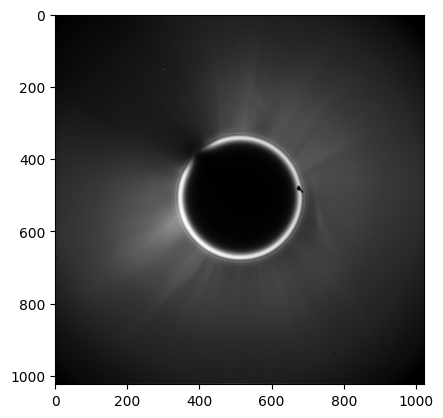

In [5]:
map0_C2 = sunpy.map.Map(file_C2[0])
plt.imshow(map0_C2.data, cmap = 'Greys_r',)

### Discussion
What features can you make out in the above image?
What might you do to increase the contrast of the above image?

## Difference image
To help increase the contrast, a image difference can be taken from two consecutive images.  

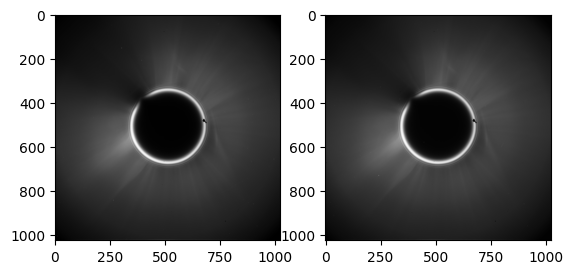

In [6]:

map0_C2 = sunpy.map.Map(file_C2[0])
map1_C2 = sunpy.map.Map(file_C2[1])

fig, ax = plt.subplots(1,2)
ax[0].imshow(map0_C2.data, cmap = 'Greys_r',)
ax[1].imshow(map1_C2.data, cmap = 'Greys_r',)

To compare two plots, we can literally take the difference between them. These so-called "difference images" shows which structures are changing between the two. This is a way of bringing out features that are evolving in time.  

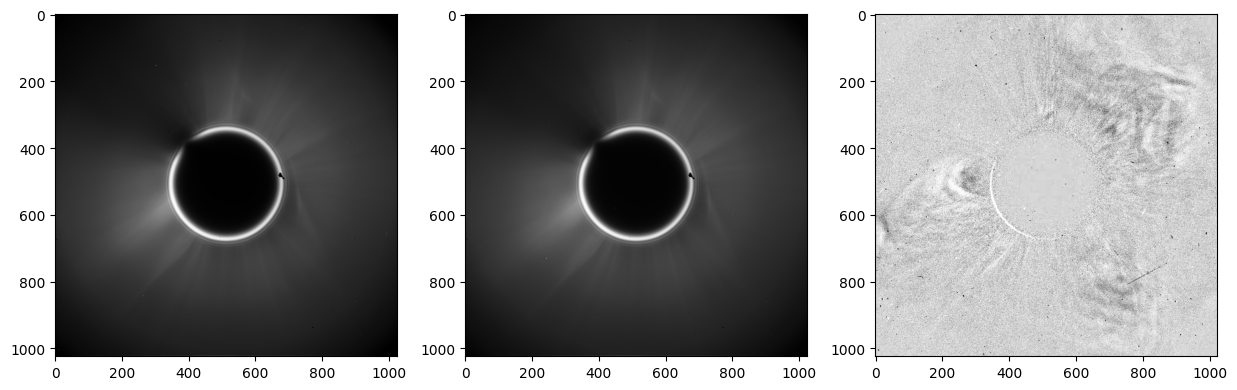

In [7]:
map0_norm = map0_C2.data / map0_C2.exposure_time.value
map1_norm = map1_C2.data / map1_C2.exposure_time.value

diff = map1_norm - map0_norm

fig, ax = plt.subplots(1,3, figsize = (15,45))
ax[0].imshow(map0_C2.data, cmap = 'Greys_r',)
ax[1].imshow(map1_C2.data, cmap = 'Greys_r',)
ax[2].imshow(diff.data, cmap='Greys_r',vmin=-3, vmax=3)

/tmp/ipykernel_1019/2814095435.py:22: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout() # Adjust layout to prevent overlapping titles/labels


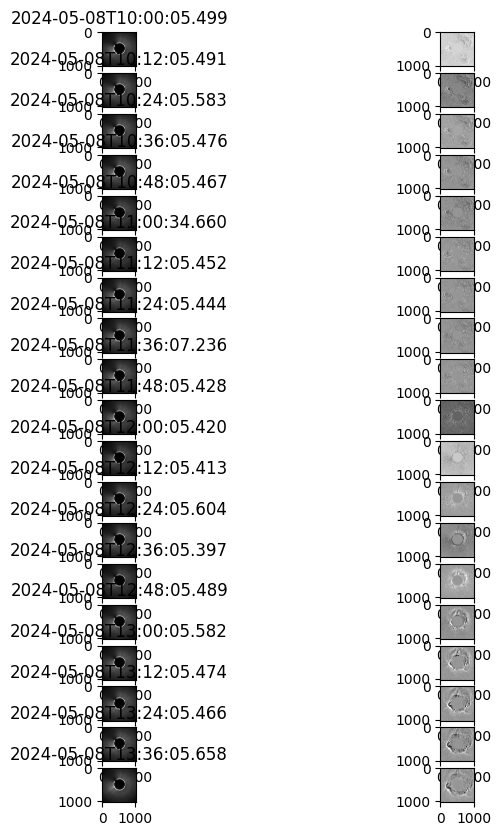

In [8]:
N = len(file_C2) # number of images downloaded in the time interval
map_C2 = [] #create an empty list for the images
map_norm = [] # create an empty list for the normalization
diff_images = [] # Create an empty list to store difference images

max = N
#max = 5
for i in range(0,max): #loop that takes a difference btween
    map_C2.append(sunpy.map.Map(file_C2[i]))
    map_norm.append(map_C2[i].data / map_C2[i].exposure_time.value)

for i in range(0, max - 1):
    diff = map_norm[i+1] - map_norm[i] #take the difference between current image and the next image
    diff_images.append(diff) # Store the difference image

fig, ax = plt.subplots(max-1,2, figsize = (8,10))
for i in range(0,max-1):
    ax[i,0].imshow(map_norm[i], cmap = 'Greys_r',) # display the current image
    ax[i,0].set_title(map_C2[i].date)
    diff = map_norm[i+1] - map_norm[i] #take the difference between current image and the next image
    ax[i,1].imshow(diff, cmap='Greys_r',vmin=-3, vmax=3) #display the difference image.
plt.tight_layout() # Adjust layout to prevent overlapping titles/labels

In [9]:
import matplotlib.animation as animation

fig, ax = plt.subplots(figsize=(4, 4))
ax.axis('off') # Hide axes

# Initialize the image with the first difference image
img = ax.imshow(diff_images[0], cmap='Greys_r', vmin=-3, vmax=3)

def animate(i):
    img.set_array(diff_images[i])
    ax.set_title(map_C2[i].date)
    return [img]

ani = animation.FuncAnimation(
    fig,
    animate,
    frames=len(diff_images),
    interval=200, # Milliseconds between frames
    blit=True,
    repeat=True
)

# To display in Colab, you might need to save it or use HTML display
# ani.save('difference_movie.mp4', writer='ffmpeg') # Uncomment to save as mp4
from IPython.display import HTML
HTML(ani.to_jshtml())


Output hidden; open in https://colab.research.google.com to view.

### Discussion
- How would you describe this image? What features can you see?
- Is the contrast good?
Try playing with 'vmin' and 'vmax'.  See how that works in the cell below.

In [10]:
# Copy the above cell and change the contrast by adjusting vmin and vmax.

## Compare to LASCO-C3
Use the previous code to explore C3 coronagraph imagery

In [11]:
# Copy and modify code to search for and download the needed files

In [12]:
# Extract images, create difference image, and plot all.

## Find CME's
Using the dates and times from the GOES X-Ray data and SDO AIA images, find the CME's launched in this period.

- Which of the CME's you found are heading towards Earth? How can you tell?